<a href="https://colab.research.google.com/github/Dhanuxh266/231A038_NLP_Experiments/blob/main/NLP_Assignment_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Name : Dhanush Pallan / Uin No. : 231a038")
!pip -q install sentence-transformers pypdf python-docx pandas matplotlib seaborn

Name : Dhanush Pallan / Uin No. : 231a038
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.1/405.1 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 11.6 MB/s eta 0:00:00


In [2]:
print("Name : Dhanush Pallan / Uin No. : 231a038")
sample_contract = """
SERVICE AGREEMENT

1. PAYMENT:
The client shall pay the service provider INR 50,000
within 30 days of receiving the invoice.

2. TERMINATION:
The service provider may terminate this agreement
at any time without prior notice to the client.

3. CONFIDENTIALITY:
Both parties shall keep confidential information secret
during the agreement and for two years thereafter.

4. LIABILITY:
The service provider shall not be liable for any direct,
indirect, incidental, or consequential damages.

5. DATA PRIVACY:
The client shall ensure that all personal data is
collected and processed in accordance with applicable laws.

6. DISPUTE RESOLUTION:
All disputes shall be subject to the jurisdiction of
courts in Mumbai, Maharashtra.

7. PENALTY:
The client must pay a penalty of INR 10,000 for every
day of delay, without any maximum limit.
"""

print(sample_contract)

Name : Dhanush Pallan / Uin No. : 231a038

SERVICE AGREEMENT

1. PAYMENT:
The client shall pay the service provider INR 50,000
within 30 days of receiving the invoice.

2. TERMINATION:
The service provider may terminate this agreement
at any time without prior notice to the client.

3. CONFIDENTIALITY:
Both parties shall keep confidential information secret
during the agreement and for two years thereafter.

4. LIABILITY:
The service provider shall not be liable for any direct,
indirect, incidental, or consequential damages.

5. DATA PRIVACY:
The client shall ensure that all personal data is
collected and processed in accordance with applicable laws.

6. DISPUTE RESOLUTION:
All disputes shall be subject to the jurisdiction of
courts in Mumbai, Maharashtra.

7. PENALTY:
The client must pay a penalty of INR 10,000 for every
day of delay, without any maximum limit.



In [3]:
print("Name : Dhanush Pallan / Uin No. : 231a038")
import re
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sentence_transformers import SentenceTransformer, util

Name : Dhanush Pallan / Uin No. : 231a038


In [4]:
print("Name : Dhanush Pallan / Uin No. : 231a038")
from google.colab import files
from pypdf import PdfReader
from docx import Document
import os

def load_legal_document(upload_file=False):
    if not upload_file:
        return sample_contract

    uploaded = files.upload()

    if not uploaded:
        raise ValueError("No file uploaded.")

    filename = next(iter(uploaded))

    if filename.lower().endswith(".pdf"):
        reader = PdfReader(filename)
        text = "\n".join(
            page.extract_text() or "" for page in reader.pages
        )

    elif filename.lower().endswith(".docx"):
        document = Document(filename)
        text = "\n".join(p.text for p in document.paragraphs)

    elif filename.lower().endswith(".txt"):
        with open(filename, "r", encoding="utf-8-sig") as f:
            text = f.read()

    else:
        raise ValueError("Upload a PDF, DOCX, or TXT file.")

    if not text.strip():
        raise ValueError(
            "No readable text found. The PDF may require OCR."
        )

    return text

# Keep False for the first run.
contract_text = load_legal_document(upload_file=False)

print(contract_text[:5000])

Name : Dhanush Pallan / Uin No. : 231a038

SERVICE AGREEMENT

1. PAYMENT:
The client shall pay the service provider INR 50,000
within 30 days of receiving the invoice.

2. TERMINATION:
The service provider may terminate this agreement
at any time without prior notice to the client.

3. CONFIDENTIALITY:
Both parties shall keep confidential information secret
during the agreement and for two years thereafter.

4. LIABILITY:
The service provider shall not be liable for any direct,
indirect, incidental, or consequential damages.

5. DATA PRIVACY:
The client shall ensure that all personal data is
collected and processed in accordance with applicable laws.

6. DISPUTE RESOLUTION:
All disputes shall be subject to the jurisdiction of
courts in Mumbai, Maharashtra.

7. PENALTY:
The client must pay a penalty of INR 10,000 for every
day of delay, without any maximum limit.



In [6]:
print("Name : Dhanush Pallan / Uin No. : 231a038")
def split_into_clauses(text):
    # Split at numbered headings such as "1. PAYMENT:"
    parts = re.split(
        r"(?m)(?=^\s*\d+\.\s+[A-Z][A-Z /-]*:)",
        text.strip()
    )

    clauses = []

    for part in parts:
        part = part.strip()

        if len(part) > 20:
            clauses.append(part)

    return clauses

clauses = split_into_clauses(contract_text)

for i, clause in enumerate(clauses, start=1):
    print(f"\nCLAUSE {i}\n{clause}")

print("\nTotal clauses detected:", len(clauses))

Name : Dhanush Pallan / Uin No. : 231a038

CLAUSE 1
1. PAYMENT:
The client shall pay the service provider INR 50,000
within 30 days of receiving the invoice.

CLAUSE 2
2. TERMINATION:
The service provider may terminate this agreement
at any time without prior notice to the client.

CLAUSE 3
3. CONFIDENTIALITY:
Both parties shall keep confidential information secret
during the agreement and for two years thereafter.

CLAUSE 4
4. LIABILITY:
The service provider shall not be liable for any direct,
indirect, incidental, or consequential damages.

CLAUSE 5
5. DATA PRIVACY:
The client shall ensure that all personal data is
collected and processed in accordance with applicable laws.

CLAUSE 6
6. DISPUTE RESOLUTION:
All disputes shall be subject to the jurisdiction of
courts in Mumbai, Maharashtra.

CLAUSE 7
7. PENALTY:
The client must pay a penalty of INR 10,000 for every
day of delay, without any maximum limit.

Total clauses detected: 7


In [7]:
print("Name : Dhanush Pallan / Uin No. : 231a038")
risk_rules = {
    "Payment": [
        "payment", "pay", "invoice", "fee", "amount"
    ],
    "Termination": [
        "terminate", "termination", "without prior notice"
    ],
    "Confidentiality": [
        "confidential", "confidentiality", "secret"
    ],
    "Liability": [
        "liable", "liability", "damages", "indemnity"
    ],
    "Data Privacy": [
        "personal data", "privacy", "processed", "consent"
    ],
    "Dispute Resolution": [
        "dispute", "jurisdiction", "arbitration", "court"
    ],
    "Penalty": [
        "penalty", "fine", "per day", "without any maximum limit"
    ]
}

risk_keywords = [
    "without prior notice",
    "not be liable",
    "without any maximum limit",
    "unlimited",
    "sole discretion",
    "penalty"
]

def rule_based_analyzer(clause):
    text = clause.lower()

    detected_categories = [
        category
        for category, keywords in risk_rules.items()
        if any(keyword in text for keyword in keywords)
    ]

    detected_risks = [
        keyword for keyword in risk_keywords
        if keyword in text
    ]

    return {
        "categories": detected_categories,
        "risk_flags": detected_risks or ["No predefined risk keyword found"]
    }

rule_results = []

for clause in clauses:
    result = rule_based_analyzer(clause)

    rule_results.append({
        "Clause": clause.split("\n")[0][:50],
        "Categories": ", ".join(result["categories"]),
        "Risk Flags": ", ".join(result["risk_flags"])
    })

rule_df = pd.DataFrame(rule_results)
display(rule_df)

Name : Dhanush Pallan / Uin No. : 231a038


,Clause,Categories,Risk Flags
0,1. PAYMENT:,Payment,No predefined risk keyword found
1,2. TERMINATION:,Termination,without prior notice
2,3. CONFIDENTIALITY:,Confidentiality,No predefined risk keyword found
3,4. LIABILITY:,Liability,not be liable
4,5. DATA PRIVACY:,Data Privacy,No predefined risk keyword found
5,6. DISPUTE RESOLUTION:,Dispute Resolution,No predefined risk keyword found
6,7. PENALTY:,"Payment, Penalty","without any maximum limit, penalty"


In [8]:
print("Name : Dhanush Pallan / Uin No. : 231a038")
model = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

category_descriptions = {
    "Payment": "A clause describing fees, invoices, payments, or financial obligations.",
    "Termination": "A clause describing cancellation, termination, or ending a contract.",
    "Confidentiality": "A clause requiring parties to protect confidential information.",
    "Liability": "A clause limiting responsibility for losses, damages, or legal claims.",
    "Data Privacy": "A clause concerning personal information, data protection, and consent.",
    "Dispute Resolution": "A clause describing courts, jurisdiction, arbitration, or dispute settlement.",
    "Penalty": "A clause imposing fines, penalties, or charges for delays or breaches."
}

risk_descriptions = {
    "Unilateral termination": (
        "One party can end the contract without notice "
        "or without giving the other party protection."
    ),
    "Liability exclusion": (
        "A party excludes responsibility for losses or damages."
    ),
    "Uncapped penalty": (
        "A contract imposes a penalty with no maximum monetary limit."
    ),
    "Ambiguous obligation": (
        "A contract obligation is vague, unclear, or difficult to measure."
    )
}

category_names = list(category_descriptions.keys())
category_texts = list(category_descriptions.values())

risk_names = list(risk_descriptions.keys())
risk_texts = list(risk_descriptions.values())

category_embeddings = model.encode(
    category_texts, convert_to_tensor=True
)
risk_embeddings = model.encode(
    risk_texts, convert_to_tensor=True
)

def semantic_analyzer(clause):
    clause_embedding = model.encode(
        clause, convert_to_tensor=True
    )

    category_scores = util.cos_sim(
        clause_embedding, category_embeddings
    )[0]

    risk_scores = util.cos_sim(
        clause_embedding, risk_embeddings
    )[0]

    best_category_index = int(category_scores.argmax())
    best_risk_index = int(risk_scores.argmax())

    return {
        "category": category_names[best_category_index],
        "category_similarity": float(
            category_scores[best_category_index]
        ),
        "possible_risk": risk_names[best_risk_index],
        "risk_similarity": float(risk_scores[best_risk_index])
    }

semantic_results = []

for clause in clauses:
    result = semantic_analyzer(clause)

    semantic_results.append({
        "Clause": clause.split("\n")[0][:50],
        "Predicted Category": result["category"],
        "Category Similarity": round(
            result["category_similarity"], 3
        ),
        "Possible Risk": result["possible_risk"],
        "Risk Similarity": round(
            result["risk_similarity"], 3
        )
    })

semantic_df = pd.DataFrame(semantic_results)
display(semantic_df)

Name : Dhanush Pallan / Uin No. : 231a038


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,Clause,Predicted Category,Category Similarity,Possible Risk,Risk Similarity
0,1. PAYMENT:,Payment,0.392,Ambiguous obligation,0.169
1,2. TERMINATION:,Termination,0.686,Unilateral termination,0.623
2,3. CONFIDENTIALITY:,Confidentiality,0.729,Unilateral termination,0.460
3,4. LIABILITY:,Liability,0.454,Liability exclusion,0.360
4,5. DATA PRIVACY:,Data Privacy,0.649,Ambiguous obligation,0.154
5,6. DISPUTE RESOLUTION:,Dispute Resolution,0.606,Ambiguous obligation,0.234
6,7. PENALTY:,Penalty,0.600,Uncapped penalty,0.414


In [9]:
print("Name : Dhanush Pallan / Uin No. : 231a038")
comparison_df = pd.DataFrame({
    "Clause": [
        c.split("\n")[0].strip() for c in clauses
    ],
    "Rule-Based Categories": [
        r["Categories"] for r in rule_results
    ],
    "Rule-Based Risk Flags": [
        r["Risk Flags"] for r in rule_results
    ],
    "Semantic Category": semantic_df["Predicted Category"],
    "Semantic Possible Risk": semantic_df["Possible Risk"]
})

display(comparison_df)

Name : Dhanush Pallan / Uin No. : 231a038


,Clause,Rule-Based Categories,Rule-Based Risk Flags,Semantic Category,Semantic Possible Risk
0,1. PAYMENT:,Payment,No predefined risk keyword found,Payment,Ambiguous obligation
1,2. TERMINATION:,Termination,without prior notice,Termination,Unilateral termination
2,3. CONFIDENTIALITY:,Confidentiality,No predefined risk keyword found,Confidentiality,Unilateral termination
3,4. LIABILITY:,Liability,not be liable,Liability,Liability exclusion
4,5. DATA PRIVACY:,Data Privacy,No predefined risk keyword found,Data Privacy,Ambiguous obligation
5,6. DISPUTE RESOLUTION:,Dispute Resolution,No predefined risk keyword found,Dispute Resolution,Ambiguous obligation
6,7. PENALTY:,"Payment, Penalty","without any maximum limit, penalty",Penalty,Uncapped penalty


In [10]:
print("Name : Dhanush Pallan / Uin No. : 231a038")
expected_categories = [
    "Payment",
    "Termination",
    "Confidentiality",
    "Liability",
    "Data Privacy",
    "Dispute Resolution",
    "Penalty"
]

comparison_df["Expected Category"] = expected_categories

comparison_df["Rule-Based Match"] = [
    expected in detected.split(", ")
    for expected, detected in zip(
        expected_categories,
        comparison_df["Rule-Based Categories"]
    )
]

comparison_df["Semantic Match"] = (
    comparison_df["Expected Category"]
    == comparison_df["Semantic Category"]
)

display(comparison_df)

Name : Dhanush Pallan / Uin No. : 231a038


,Clause,Rule-Based Categories,Rule-Based Risk Flags,Semantic Category,Semantic Possible Risk,Expected Category,Rule-Based Match,Semantic Match
0,1. PAYMENT:,Payment,No predefined risk keyword found,Payment,Ambiguous obligation,Payment,True,True
1,2. TERMINATION:,Termination,without prior notice,Termination,Unilateral termination,Termination,True,True
2,3. CONFIDENTIALITY:,Confidentiality,No predefined risk keyword found,Confidentiality,Unilateral termination,Confidentiality,True,True
3,4. LIABILITY:,Liability,not be liable,Liability,Liability exclusion,Liability,True,True
4,5. DATA PRIVACY:,Data Privacy,No predefined risk keyword found,Data Privacy,Ambiguous obligation,Data Privacy,True,True
5,6. DISPUTE RESOLUTION:,Dispute Resolution,No predefined risk keyword found,Dispute Resolution,Ambiguous obligation,Dispute Resolution,True,True
6,7. PENALTY:,"Payment, Penalty","without any maximum limit, penalty",Penalty,Uncapped penalty,Penalty,True,True


In [11]:
print("Name : Dhanush Pallan / Uin No. : 231a038")
rule_accuracy = comparison_df["Rule-Based Match"].mean() * 100
semantic_accuracy = comparison_df["Semantic Match"].mean() * 100

print(f"Rule-based category match: {rule_accuracy:.1f}%")
print(f"Semantic category match: {semantic_accuracy:.1f}%")

Name : Dhanush Pallan / Uin No. : 231a038
Rule-based category match: 100.0%
Semantic category match: 100.0%


Name : Dhanush Pallan / Uin No. : 231a038


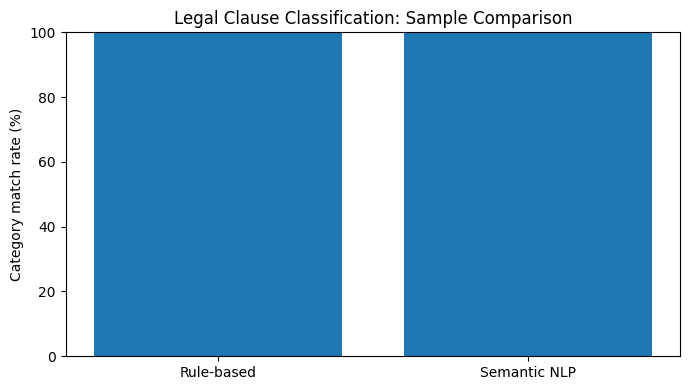

In [12]:
print("Name : Dhanush Pallan / Uin No. : 231a038")
plt.figure(figsize=(7, 4))

plt.bar(
    ["Rule-based", "Semantic NLP"],
    [rule_accuracy, semantic_accuracy]
)

plt.ylim(0, 100)
plt.ylabel("Category match rate (%)")
plt.title("Legal Clause Classification: Sample Comparison")
plt.tight_layout()
plt.show()